# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [4]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [5]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [6]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [7]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [8]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


- Los tipos de dato por columna son correctos. No hay presencia de valores nulos.

In [9]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


- La columna city presenta 469 valores nulos.
- Fecha de registro (ref_date) y fecha de cancelación (churn_date) requiere conversión a tipo de dato: **datetime**
- Los valores ausentes en fecha de cancelación (churn_date) se considera que los clientes aún están vigentes. 

In [10]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


- La columna date presenta 50 entradas nulas y es necesario convertir el tipo de dato a datetime.
- Se considera que la suma del número de entradas entre duration y length son 40000, pues los minutos corresponden a las llamadas y el número de caracteres a los mensajes, por lo tanto 28 entradas cuentan con ambos datos.

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [11]:
# cantidad de nulos para users

print("Valores nulos por columna en dataset users:")
print(users.isna().sum())
print()
print("Porcentaje de valores nulos por columna en dataset users:")
print(users.isna().mean().sort_values(ascending=False))


Valores nulos por columna en dataset users:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Porcentaje de valores nulos por columna en dataset users:
churn_date    0.88350
city          0.11725
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
reg_date      0.00000
plan          0.00000
dtype: float64


In [12]:
# cantidad de nulos para usage
print("Valores nulos por columna en dataset usage:")
print(usage.isna().sum())
print()
print("Porcentaje de valores nulos por columna en dataset usage:")
print(usage.isna().mean().sort_values(ascending=False))

Valores nulos por columna en dataset usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Porcentaje de valores nulos por columna en dataset usage:
duration    0.55190
length      0.44740
date        0.00125
id          0.00000
user_id     0.00000
type        0.00000
dtype: float64


✍️ **HALLAZGOS Y RECOMENDACIONES**:
- **Columna churn_date:** se recomienda ignorar esta columna, pues tiene un 88.3% de valores nulos, por lo que no sería acertado imputar datos, ni eliminarlos, ya que nos haría perder información valiosa de otras columnas.
- **Columna city:** Si posteriormente esta columna se utilizará para evaluar el uso de los planes de teléfono por ciudad, se recomienda imputar los valores faltantes como unknown, si no, no es neceario hacerlo. De ser necesaria la imputación y tomando en cuenta que el porcentaje de nulos de la columna city es 11.72%, se revisa que la probabilidad que estos missings estén ligados a otra variable es minima, ya que a la unica variable a la que podría estar ligada este tipo de valor nulo es a la fecha de registro.
- **Columna date:** al tener un 0.12% de nulos, se recomienda dejar como nulos, ya que por el momento no estamos interesados en evaluar información que involucre conocer la fecha de llamadas o mensajes.
- **Columnas duration y length:** en este caso tenemos 40 mil entradas, para llamada o mensaje, cuando es llamada viene informacion de duración y cuando es mensaje la longitud del mismo, por lo que es normal que haya tantos nulos en ambas columnas. La suma de valores no nulos entre ambas columnas da 40028, siendo un total de entradas de 40000, por lo que 28 filas contienen datos en ambas columnas, por ello, se sugiere revisar aquellas con datos en ambas, y dejar el valor que corresponde según el tipo de uso.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [13]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id`: este es el numero de identificación del usuario, nos indica que nuestros dataset cuenta con 4000 entradas.
- La columna `age`: la columna age contiene sentinels que pueden estar afectando la estadistica, generando que la media sea menor a la real y la desviación estándar muestra una variación muy alta entre edades, es necesario corregir y limpiar estos datos aberrantes.

In [14]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` son columnas para identificar al cliente, por lo que estadisticamente y considerando las metricas a evaluar, son poco reelevantes para este ejercicio.
- Las columnas duration y length contienen valores mínimos y máximos realistas, no contienen valores negativos que pudieran indicar presencia de valores aberrantes. la media de la columna duration es mayor a la mediana, lo que indica que hay eventos aleatorios muy altos, que impactan en la media, además la desviación estandar sugiere que hay una alta disperción en el tiempo de llamadas, por otro lado, length tiene una media y una mediana similares, lo que indica que la mayoria de los datos se concentran en 50 caracteres, sin embargo, la distribución presenta sesgo a la derecha.

In [15]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(users[col].describe())
    print()
    print(f"Valores unicos en {col}:", users[col].unique())
    print("------")

count       3531
unique         7
top       Bogotá
freq         808
Name: city, dtype: object

Valores unicos en city: ['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
------
count       4000
unique         2
top       Basico
freq        2595
Name: plan, dtype: object

Valores unicos en plan: ['Basico' 'Premium']
------


- La columna `city` presenta valores nulos y sentinels. La ciudad más frecuente es Bogotá.
- La columna `plan` presenta valores esperados, sólo se tienen 2 categorias. Las mismas que podemos ver en el dataframe de plans, siendo el plan básico el más frecuente.

In [16]:
# explorar columna categórica de usage
print(usage['type'].describe())
print()
print("Valores unicos en type",usage['type'].unique())

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

Valores unicos en type ['call' 'text']


- La columna `type` nos indica que el tipo de uso más frecuente es el mensaje de texto.

---
✍️ **Comentario**: La columna city requiere una limpieza de datos, para tratar sentinels y valores nulos. Se recomendaría imputar estos valores a tipo de ciudad "unknown" para evitar la perdida de información relacionada al tipo de uso por los usuarios.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels? La columna city es la unica que presenta sentinels.
- ¿Qué acción tomarías? se recomienda imputar con unknown, para no perder información del tipo de uso, debido a que no es posible determinar la ciudad en estos casos.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'],errors="coerce")

In [18]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'],errors="coerce")

In [19]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date` se observa que el periodo de registro de usuarios a evaluar es entre 2022 y 2026. Interesante revisar que intencionalmente se esté excluyendo el año 2025 y que el año 2026 tiene una aportación mínima de datos en comparación con los años previos.
Basaremos el análisis en estas fechas.

In [20]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts()

2024.0    39950
Name: date, dtype: int64

En `date` observamos que sólo contamos con fechas de uso en 2024. Esto quiere decir que los usuarios que nos interesan son aquellos que se registraron entre 2022 y 2024.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:
- Observamos que la intención es evaluar exclusivamente el uso que dieron los usuarios durante el año 2024, lo cual, con lo mencionado con el punto anterior, es congruente que no aparezcan datos de usuarios registrados en 2025 y haya una cantidad minima de usuarios registrados en 2026, por lo que se recomienda excluir aquellos usuarios que se registraron posterior al año 2024.

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? Si, toda la información obtenida para evaluar las metricas de uso, fue recolectada durante el año 2024, por lo que aquellos usuarios que se registraron posterior a este año, quedarían excluidos del análisis.
- ¿Qué harías con ellas? Se recomienda eliminar aquellos usuarios registrados posterior al año 2024.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [21]:
# Reemplazar -999 por la mediana de age
users['age'] = users['age'].replace([-999],pd.NA)
age_mediana = users['age'].median()
users['age'] = users['age'].fillna(age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace(['?'],pd.NA)

# Verificar cambios
print(f"Valores unicos en city", users["city"].unique())


Valores unicos en city ['Medellín' <NA> 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']


In [23]:
# Marcar fechas futuras como NA para reg_date

users['reg_date']= users['reg_date'].dt.year
users.loc[users['reg_date']>2024,'reg_date'] =pd.NA


# Verificar cambios
users['reg_date'].value_counts()

2024    1330
2023    1316
2022    1314
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [24]:
# Verificación MAR en usage (Missing At Random) para duration
usage["duration"].isna().groupby(usage["type"]).mean()

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [25]:
# Verificación MAR en usage (Missing At Random) para length
usage["length"].isna().groupby(usage["type"]).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

**Diagnostico de nulos en `duration` y `length`:**
- los nulos presentes en ambas columnas siguen un patron externo por lo que se catalogan como tipos de nulos MAR, ya que dependen de otra variable, en este caso el tipo de uso, lo cual es congruente debido a que la duración en tiempo esta relacionada a llamadas y ausente en mensajes, y por otro lado la longitud de caracteres está presente siempre que tenemos tipo de mensaje y ausente en el 99.93% en llamadas. 

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [26]:


# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({"is_text":"sum","is_call":"sum","duration":"sum"}).reset_index()

# observar resultado
usage_agg.head(3)



,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Renombrar columnas
usage_agg= usage_agg.rename(columns={"is_text":"cant_mensajes","is_call":"cant_llamadas","duration":"cant_minutos_llamada"})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = usage_agg.merge(users,on="user_id",how="left")
user_profile.head(5)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022,Basico,NaN
1,10001,5,10,33.18,Mateo,Torres,53.0,<NA>,2022,Basico,NaN
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022,Basico,NaN
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022,Premium,NaN
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022,Basico,NaN


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [29]:
# Resumen estadístico de las columnas numéricas
user_profile[['cant_mensajes','cant_llamadas','cant_minutos_llamada','age']].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada,age
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054,48.138285
std,2.358416,2.144238,18.168095,17.691541
min,0.000000,0.000000,0.000000,18.000000
25%,4.000000,3.000000,11.120000,33.000000
50%,5.000000,4.000000,19.780000,48.000000
75%,7.000000,6.000000,31.415000,63.000000
max,17.000000,15.000000,155.690000,79.000000


In [30]:
# Distribución porcentual del tipo de plan
porcentaje_basico= round(((user_profile["plan"]=="Basico").mean()*100),2)
porcentaje_premium= round(((user_profile["plan"]=="Premium").mean()*100),2)

print("Porcentaje de usuarios con plan Básico:",porcentaje_basico)
print()
print("Porcentaje de usuarios con plan Premium:",porcentaje_premium)

Porcentaje de usuarios con plan Básico: 64.87

Porcentaje de usuarios con plan Premium: 35.13


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

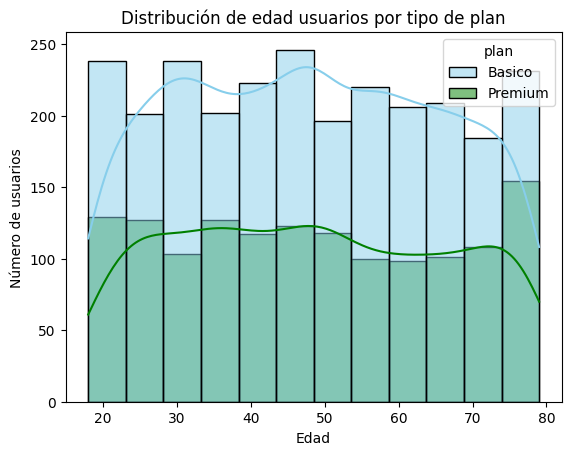

In [31]:
# Histograma para visualizar la edad (age)

sns.histplot(data=user_profile,
    x="age",
    bins=12,
    hue= "plan",
    kde=True,
    palette=['skyblue','green']    
)

plt.title("Distribución de edad usuarios por tipo de plan")
plt.xlabel("Edad")
plt.ylabel("Número de usuarios")
plt.show()


💡Insights: 
- Distribución uniforme, la curva de KDE no muestra una tendencia pronunciada por edad. Las frecuencia se mantiene relativamente contante y no se identifica una concentración significativa de clientes en un rango de edad específico. Se observa que claramente la suscripción Basica casi duplica a las suscripciones premium.

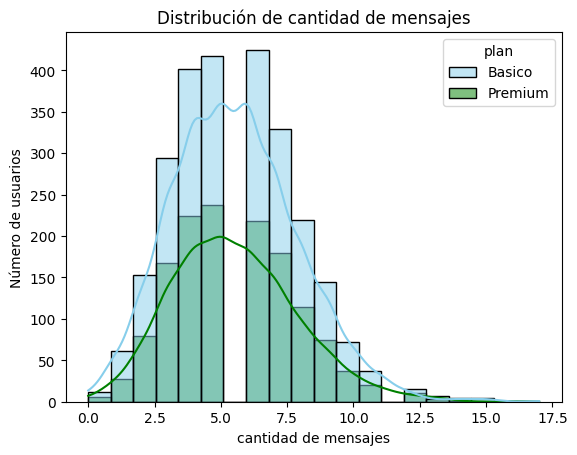

In [32]:
# Histograma para visualizar la cant_mensajes

sns.histplot(data=user_profile,
    x="cant_mensajes",
    bins=20,
    hue= "plan",
    kde=True,
    palette=['skyblue','green']    
)

plt.title("Distribución de cantidad de mensajes")
plt.xlabel("cantidad de mensajes")
plt.ylabel("Número de usuarios")
plt.show()


💡Insights: 
- Observamos una distribución que presenta un comportamiento unimodal,una distribución con una frecuencia marcada pero con ligero sesgo a la derecha, en la que observamos que la mayoria de usuarios realizan entre 3 y 7, con una mediana de 5 mensajes por usuario. El plan básico registra una frecuencia absoluta de mensajes mayor.

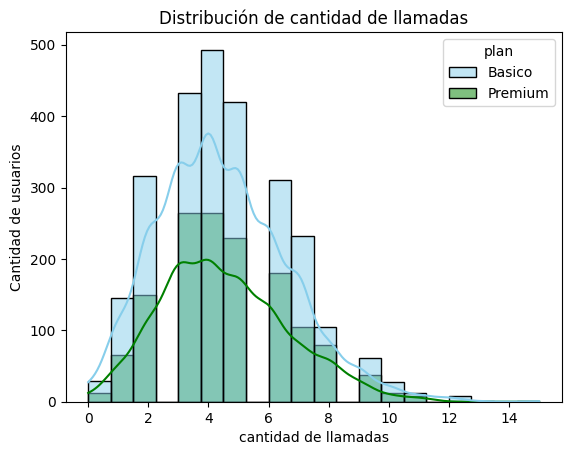

In [33]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile,
    x="cant_llamadas",
    bins=20,
    hue= "plan",
    kde=True,
    palette=['skyblue','green']    
)

plt.title("Distribución de cantidad de llamadas")
plt.xlabel("cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
- Distribución ligeramente sesgada a la derecha, que podría indicar presencia de outliers. Este gráfico nos indica que la cantidad de llamadas por usuarios más frecuente, se encuentra entre 3 y 5 llamadas, con una mediana de 4 mensajes por usuario. De igual manera el plan básico registra una frecuencia absoluta de llamadas mayor.

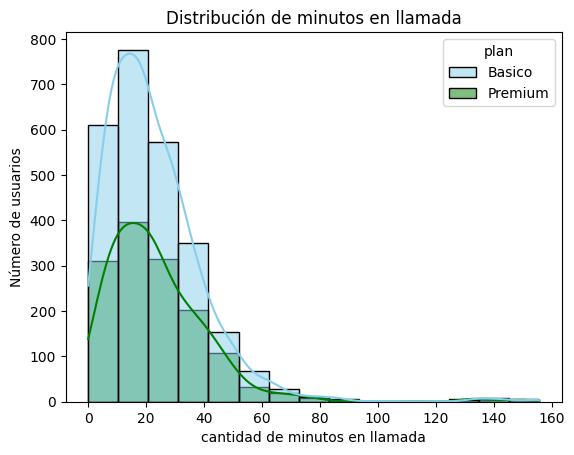

In [34]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile,
    x="cant_minutos_llamada",
    bins=15,
    hue= "plan",
    kde=True,
    palette=['skyblue','green']    
)

plt.title("Distribución de minutos en llamada")
plt.xlabel("cantidad de minutos en llamada")
plt.ylabel("Número de usuarios")
plt.show()

💡Insights: 
- Distribución sesgada la derecha con presencia de posibles outliers en ambos planes. El tiempo más frecuente de minutos en llamada es de 19.78. Siendo el plan básico el que cuenta con la mayor cantidas de usuarios en llamada.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

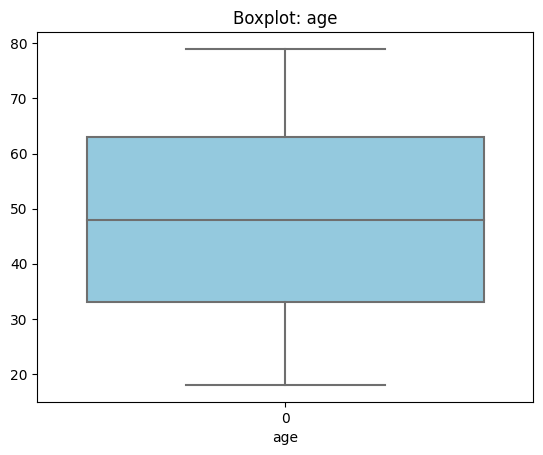

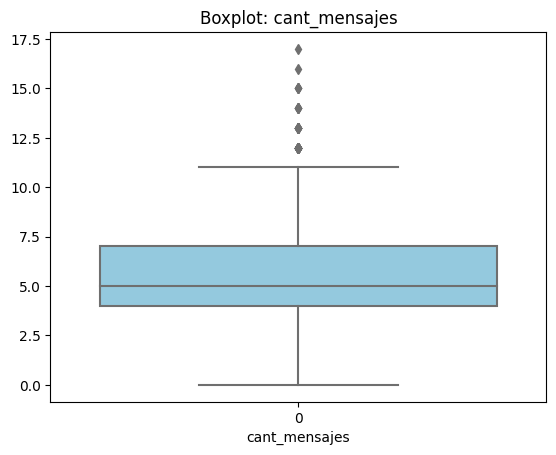

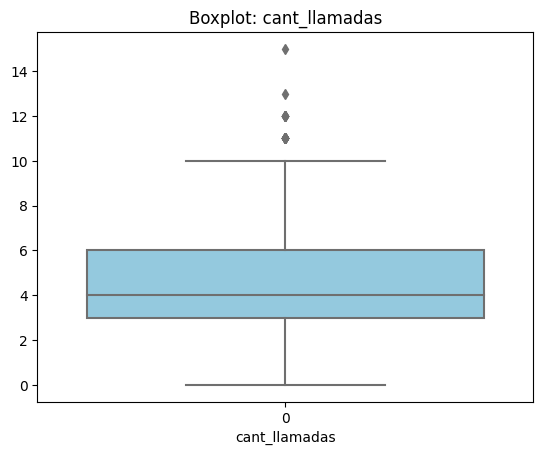

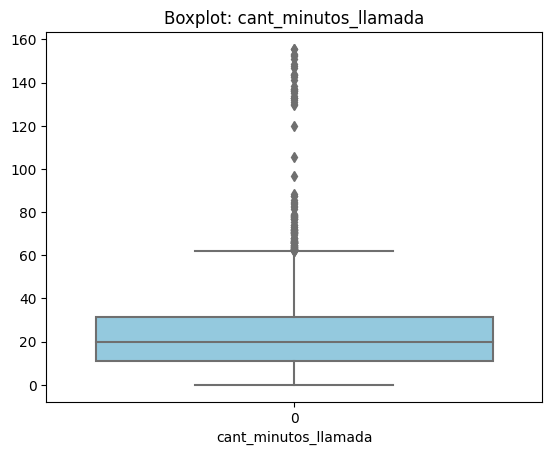

In [35]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile[col],
    color='skyblue')

    plt.title(f'Boxplot: {col}')
    plt.xlabel(f'{col}')
    plt.show()

💡Insights: 
- Age: No presenta outliers, por lo que no es necesario realizar la busqueda de valores que pudieran estar afectando la distribución
- cant_mensajes: Presenta valores atipicos que necesitan revisión.
- cant_llamadas: Presenta valores atipicos que necesitan revisión.
- cant_minutos_llamada: Presenta multiples valores atipicos que necesitan revisión.

In [44]:
# Calcular límites con el método IQR

columnas_limites = ["cant_mensajes","cant_llamadas","cant_minutos_llamada"]

for col in columnas_limites:
    Q1=user_profile[col].quantile(0.25)
    Q3=user_profile[col].quantile(0.75)
    IQR=Q3-Q1
    limite_superior=Q3+(IQR*1.5)
    print ("Limite superior para",col,":",limite_superior)



Limite superior para cant_mensajes : 11.5
Limite superior para cant_llamadas : 10.5
Limite superior para cant_minutos_llamada : 61.8575


In [37]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: El limite superior para considerar un outlier en cantidad de mensajes es de 11.5, siendo el valor máximo de 17, este se podría considerar un valor real alto, por lo que se deciden mantener los outliers superiores al límite.
- cant_llamadas: El limite superior para considerar un outlier en cantidad de llamadas es de 10.5, mientras que el valor máximo es de 15, el cual se puede considerar como un valor real y posible, por lo que se deciden mantener los valores por fuera del límite superior.
- cant_minutos_llamada: El límite superior corresponde a 61.85 min, mientras el valor máximo de minutos en llamada es de 155.69 min. Este valor máximo representa un 787% con respecto a la mediana, apesar de ello, se considera un valor real, por lo que de igual manera, se decide mantener.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [49]:
# Crear columna grupo_uso

def classify_usage(row):
    llamadas=row['cant_llamadas']
    mensajes=row['cant_mensajes']

#Segmentación
    if llamadas<5 and mensajes <5:
        return "Bajo uso"
    elif llamadas<10 and mensajes <10:
        return "Uso medio"
    else:
        return "Alto uso"
    
user_profile["grupo_uso"]=user_profile.apply(classify_usage,axis=1)


In [50]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022,Basico,NaN,Uso medio
1,10001,5,10,33.18,Mateo,Torres,53.0,<NA>,2022,Basico,NaN,Alto uso
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022,Basico,NaN,Uso medio
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022,Premium,NaN,Alto uso
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022,Basico,NaN,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [51]:


# Crear columna grupo_edad
def classify_age(row):
    edad=row['age']

#Segmentación
    if edad<30:
        return "Joven"
    elif edad<60:
        return "Adulto"
    else:
        return "Adulto Mayor"
    
user_profile["grupo_edad"]=user_profile.apply(classify_age,axis=1)



In [52]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso,grupo_edad
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022,Basico,NaN,Uso medio,Adulto
1,10001,5,10,33.18,Mateo,Torres,53.0,<NA>,2022,Basico,NaN,Alto uso,Adulto
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022,Basico,NaN,Uso medio,Adulto
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022,Premium,NaN,Alto uso,Adulto Mayor
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022,Basico,NaN,Bajo uso,Adulto Mayor


In [53]:
#Segmentación de minutos en llamada
def classify_timeoncall(row):
    tiempo_llamada=row['cant_minutos_llamada']

#Segmentación
    if tiempo_llamada<10:
        return "Poco"
    elif tiempo_llamada<30:
        return "Moderado"
    else:
        return "Alto"
    
user_profile["time_on_call"]=user_profile.apply(classify_timeoncall,axis=1)

### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

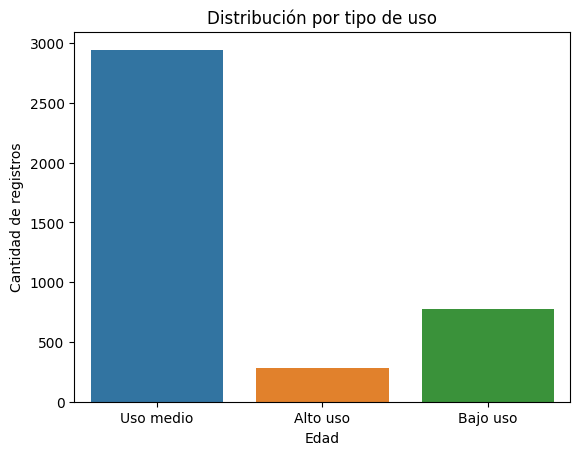

In [54]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile,
    x="grupo_uso"
    )
plt.title("Distribución por tipo de uso")
plt.xlabel("Edad")
plt.ylabel("Cantidad de registros")

plt.show()

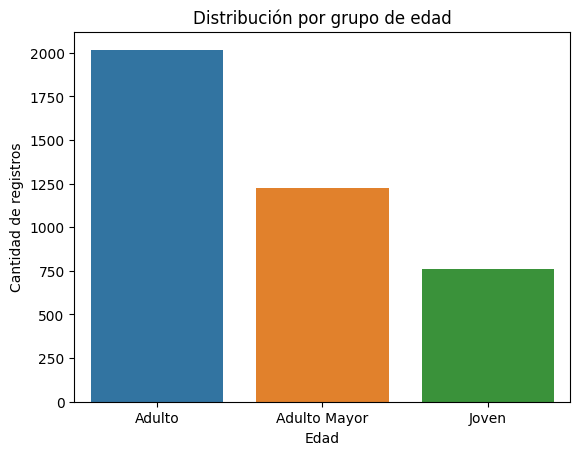

In [55]:
# Visualización de los segmentos por edad

sns.countplot(data=user_profile,
    x="grupo_edad"
    )
plt.title("Distribución por grupo de edad")
plt.xlabel("Edad")
plt.ylabel("Cantidad de registros")

plt.show()


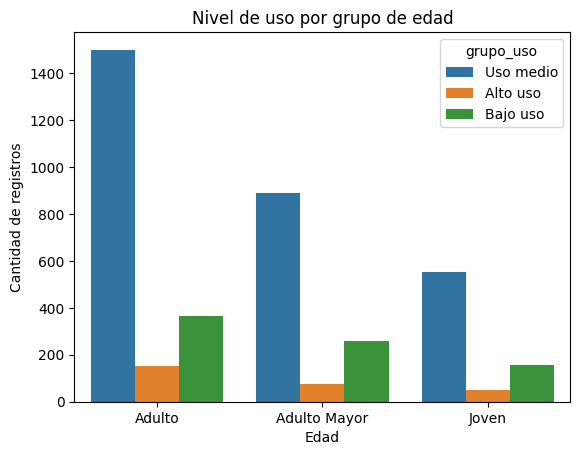

In [56]:
#Nivel de uso por edad
sns.countplot(data=user_profile,
    x="grupo_edad",
    hue="grupo_uso",
    )
plt.title("Nivel de uso por grupo de edad")
plt.xlabel("Edad")
plt.ylabel("Cantidad de registros")

plt.show()

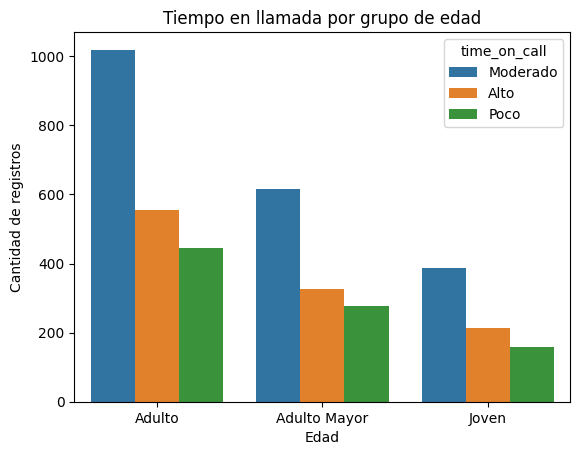

In [57]:
#Tiempo en llamada por grupo de edad
sns.countplot(data=user_profile,
    x="grupo_edad",
    hue="time_on_call",
    )
plt.title("Tiempo en llamada por grupo de edad")
plt.xlabel("Edad")
plt.ylabel("Cantidad de registros")

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**
- 

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Se detectó la presencia de valores nulos en columna city, los cuales representaban el 11.7% que correspondían a 469 registros faltantes, no fue necesaria su eliminación o imputación, ya que el objetivo del análisis no estaba enfocado la relación del uso de conectatel por ciudad.
- Se identificó el 0.125% de nulos en la columna date, del dataset usage, esto corresponde a 50 registros, debido a que el porcentaje de nulos es menor al 5%, se deciden dejar como nulos, debido a que la importancia de la variable no impactará directamente en las métricas a obtener. Se observó que el 99.87% de llamadas y mensajes se realizaron en el periodo del año 2024, por lo que se infiere que los valores nulos de está columna corresponden a este mismo año.
- Se corrigió el tipo de dato en fechas, para poder extraer el año, para observar y filtrar el periodo a evaluar los datos dentro del periodo correcto.
-Fue necesario corregir sentinels que impactaban en las métricas de edad de usuarios, y estos fueron reemplazados con la mediana. La presencia de valores aberrantes como -999 modificaban drásticamente la estadística, una vez realizada la imputación el valor mínimo pasó de -999 a 18 años.
- Se determinó que la presencia de nulos en columnas duration y length, son nulos estructurales, por la naturaleza del tipo de uso, llamada o mensaje respectivamente, por lo que se decide dejarlo.


🔍 **Segmentos por Edad**
- Se segmentó el nivel de uso en bajo, medio y alto, encontrándose que el uso medio fue el predominante, el cual corresponde a usuarios con <10 llamadas y <10 mensajes durante el periodo evaluado.


📊 **Segmentos por Nivel de Uso**
- Adicionalmente se segmentaron a los usuarios en joven <30años, adulto <60años y adulto mayor >60 años, se observa que los clientes adultos son los más frecuentes, seguido del adulto mayor.


➡️ Esto sugiere que ...
- la población de adultos representa gran parte de los clientes totales, se recomienda enfocar planes aptos para ellos, contemplando que el uso medio es el más frecuente, con la posibilidad de realizar un upgrade de su plan, para retención de clientes cuando sean usuarios de alto uso.

**Patrones de uso extremo**
- Utilizando la metodología IQR y boxplots para la identificación de outliers, se encuentran patrones de uso extremo en la cantidad de minutos en llamada, donde el valor máximo corresponde a 155 minutos, que es 150% más alto respecto al limite superior obtenido mediante IQR. 
- 2957 registros superan el valor límite, sin embargo, estos tiempos se consideran patrones normales y reales por lo que se mantienen dentro del análisis.


💡 **Recomendaciones**
- Crear un plan que se ajuste a un consumo de uso medio, permitiendo a los usuarios de uso alto pagar un upgrade adicional para mantener sus necesidades.
- Para los jovenes se sugieren planes económicos, ya que está población son quienes realizan menor cantidad de llamadas y mensajes, pudiendo deberse al uso de plataformas de redes sociales. Por ello se sugiere evaluar la información de uso de internet, para evaluar si incluir dentro de este plan personalizado el aumento de gb para navegar en internet pueda ser más atractivo para este segmento.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`